<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/heeyeon/advanced/heeyeon/session05/AI%EC%B5%9C%EC%A0%81%ED%99%94%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 전이학습
"생성모델까지 발전 이후, 어떻게 하면 더 좋은 결과?"   
효율 활용-> 전이학습, 경량화   
사람의 의도-> ai 정렬   
일 분배 -> 프롬프트 엔지니어링. 에이전트 하네스   




## 딥러닝 모델의 한계
- 성능을 내려면, 라벨링된 데이터가 대량으로 필요함
과적합 가증성이 높아질 수 밖에 없음
- 처음부터 학습하면 시간이 오래 걸리고 비용이 큼
- 학습한 데이터와 분포가 다른 데이터에서는 성능이 크게 떨어짐   
- 태스크가 바뀔 때마다 모델을 새로 학습해야 함   
-> 다른 모델 능력을 해당 태스크에 그대로 적용할 수 없을까? (전이학습 )

---

## 전이학습

### 정의 및 분류
- **정의**: 모델이 사전 학습을 통해 배운 능력을 활용해 새로운 작업을 학습하는 것   
동물 사진으로 모델 사전 학습, 특징 파악 능력을 가중치 파악 능력으로 담음. 이후 정상/폐렴 분류층으로 새롭게 교체.
이후 x ray데이터로 학습한다. 가중치 조정은 파인튜닝으로   

Source   
기존에 학습한 문제   
동물 사진으로 고양이,강아지 분류하는 문제   
Target    
새롭게 해결할 문제   
X-ray로 정상·질병 분류하는 문제   
Domain   
사용한 데이터의 특성   
일반 동물 사진 / X-ray   
Task   
수행하려는 작업   



- **분류**   
  - **귀납적 전이학습**: 소스와 타깃의 태스크가 다르고, 타깃 데이터에 라벨이 있음
  - **변환적 전이학습**: 태스크는 같고 도메인만 다름, 타깃 라벨 없음 (도메인 적응)
  - **비지도 전이학습**: 소스·타깃 모두 라벨 없음   

  -> 세션에서 더 자세히 공부하자    

---

### 패러다임
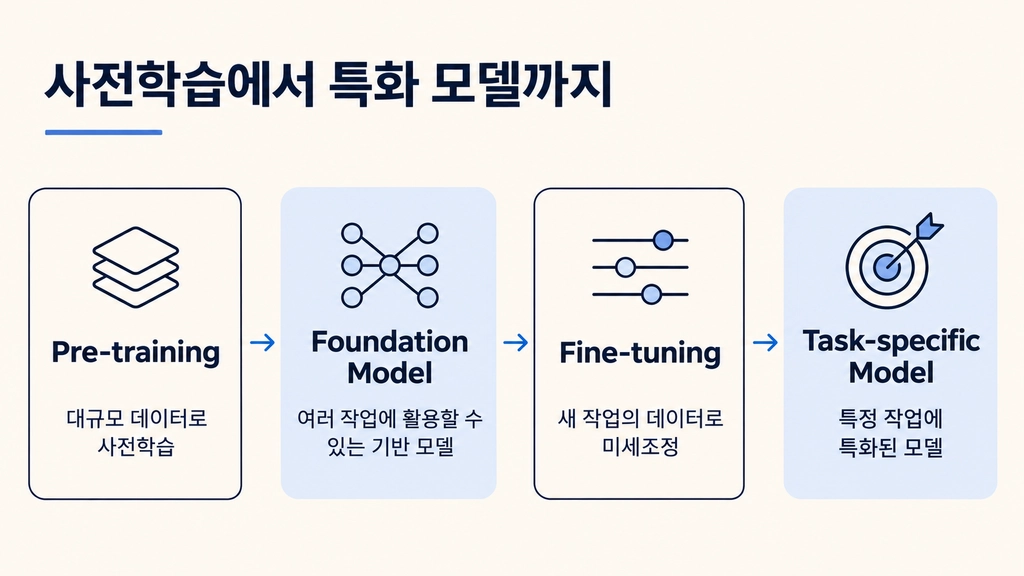
이미지 분야에서는 ImageNet처럼 정답 레이블이 붙은 대규모 이미지 데이터로 CNN을 사전 학습했었음.   
트랜스 포머 이후,   
- **특징 추출**: 사전학습 이미지 대규모 모델은 고정하고 마지막 층만 새로 학습
- **미세조정**: 언어분야에서 사전학습 모델 전체 또는 일부를 타깃 데이터로 추가 학습
- 흐름 변화: `사전학습 → 미세조정` 에서 `사전학습 → 프롬프트` 방식으로 넘어가는 중

### Foundation Model
- 하나의 모델에서 시작하여 원하는 작업에 따라 추가 학습을 진행하여 여러 특화 모델을 만들 수 있고, 시작점이 된 모델을 Foundation model, 대규모 데이터로 사전학습해 여러 태스크에 두루 쓸 수 있는 범용 모델
- 주로 자기지도학습으로 학습함
- 규모가 커지면 학습하지 않은 능력이 나타나기도 함   
- 예: GPT, BERT, CLIP

----

### Fine-tuning & PEFT
- **Full Fine-tuning**
  - 모델 전체 파라미터를 업데이트함
  - 성능은 좋지만 비용이 크고, 기존 지식을 잃는 문제(파국적 망각)가 생길 수 있음, 학습 부담이 크다   
- **PEFT (Parameter-Efficient Fine-Tuning)**
  - 파라미터 일부만 학습해서 비용을 줄이는 방식 -> 한번만 저장 후 작업별 학습 파라미터 묶음 저장   
  - *Frozen Backbone — 새롭게 판단하는 부분만 학습** : 세 방식 중에 학습 부담이 가장 작음

  ---

### 전이 학습의 한계와 활용 사례
- **한계** ndgative transfer
  - 소스와 타깃이 너무 다르면 오히려 성능이 떨어짐 (부정적 전이)
  - 파국적 망각
  - 사전학습 데이터의 편향을 그대로 물려받음
- **활용 사례**
  - 의료 영상 분석 (ImageNet 사전학습 모델 활용)
  - 감성 분석, 문서 분류 같은 NLP 태스크
  - 음성 인식

---

# 딥러닝 모델 경량화
-> 규모가 큰 Foundation Model을 메모리에 올리고 입력마다 계산을 수행해야함  

- **목적**: 모델 크기와 연산량을 줄여서 추론 속도를 높이고 메모리를 아낌, 모바일·엣지 기기 배포

- **주요 방법**
  - **가지치기 (Pruning)**: 중요도가 낮은 가중치나 뉴런 제거
  - **양자화 (Quantization)**: 32bit 실수를 8bit, 4bit 등 낮은 정밀도로 변환
  - **지식 증류 (Knowledge Distillation)**: 큰 모델(Teacher)의 출력을 작은 모델(Student)이 따라 배우게 함
  - **모델구조 경량화 설계**: 처음부터 효율적인 구조로 설계 (MobileNet 등)

---

# AI Alignment

## AI 정렬이 필요한 이유와 정렬 기준

- **이유**
  - 모델의 학습 목표(다음 토큰 예측)와 사람이 실제로 원하는 것이 다름
  - 유해한 출력, 환각, 편향 등의 문제 발생
  - 보상만 높이려고 꼼수를 쓰는 보상 해킹 문제

  사실과 다른 문장을 만들거나 사전 학습 데이터에서 생성된 편향이 드러남.


- **정렬 기준 (HHH)**
  - **Helpful**: 사용자에게 도움이 되는가
  - **Honest**: 사실대로 말하는가
  - **Harmless**: 해를 끼치지 않는가

## AI 정렬의 두 가지 관점
- **Outer Alignment**: 목표(보상 함수) 자체를 사람의 의도에 맞게 설계하는 문제, 목표를 제대로 설정했는지   
- **Inner Alignment**: 모델이 실제로 무엇을 배웠는지. 학습한 목표가 설계한 목표와 같은지의 문제

## RLHF
- 사람의 피드백으로 모델을 강화학습시키는 방법   
중요한 것은 사람의 답변 기준이라는 것   
- **단계**
  1. **SFT**: 사람이 쓴 모범 답변으로 지도학습
  2. **보상 모델 학습**: 여러 응답에 사람이 순위를 매기고, 이를 예측하는 보상 모델 학습
  3. **강화학습 (PPO 알고리즘)**: 보상 모델 점수가 높아지도록 학습, KL 페널티로 원래 모델에서 너무 벗어나지 않게 함
- **한계**: 사람 피드백 비용이 큼, 평가자 편향, 보상 해킹
- **대안**: DPO, RLAIF 등

---



# 프롬프트 엔지니어링

## Prompt vs Fine-tuning

에이아이가 더 좋은 답을 내도록 입력을 설계하는 기술   

| 구분 | Prompt | Fine-tuning |
|---|---|---|
| 모델 가중치 | 변경 없음 | 변경함 |
| 비용·시간 | 적음 | 큼 |
| 필요 데이터 | 거의 없음 | 학습 데이터 필요 |
| 유연성 | 바로 수정 가능 | 재학습 필요 |
| 적합한 경우 | 빠른 실험, 일반 태스크 | 특정 도메인·형식 고정 |

## 주요 기법
- **Zero-shot**: 예시 없이 지시만 줌
- **Few-shot**: 예시 몇 개를 같이 줌
- **Chain-of-Thought (CoT)**: 단계별로 생각하게 유도
- **Role Prompting**: 역할 부여 (예: "너는 데이터 분석가야")


## 프롬프트 엔지니어링의 한계
- 단어 하나만 바꿔도 결과가 달라질 정도로 민감함
- 그럴 듯 하게 지어내는 할루시네이션   
- 모델마다 잘 먹히는 프롬프트가 다름
- 모델이 원래 모르는 지식은 추가할 수 없음


---

# 하네스 엔지니어링

## 하네스의 정의와 구성 요소
- **정의**: 모델을 감싸서 실제 작업을 수행하게 만드는 실행 환경 전체
  - `에이전트 = 모델 + 하네스`
- **구성 요소** 여섯가지
  - 시스템 프롬프트·지시문
  - 도구 정의   
  - 메모리
  - 실행 루프
  - 권한 관리·가드레일
  - 로깅·평가

## 에이전트 실패 유형 별 하네스 개선 방법
실패는 어디서 오는가   
증상 -> 하네스 어디를 고칠 것인가?    

| 실패 유형 | 개선 방법 |
|---|---|
| 도구를 잘못 호출함 | 도구 설명 명확히 작성, 입력값 검증 |
| 앞의 정보를 잊어버림 | 요약, 외부 메모리, 컨텍스트 압축 |
| 같은 행동을 무한 반복함 | 최대 반복 횟수 제한, 진행 상황 체크 |
| 일을 다 안 하고 끝냄 | 완료 조건 명시, 마지막 검증 단계 추가 |
| 환각 | 검색으로 근거 확보, 출처 확인 |
| 위험한 행동 | 권한 제한, 사람 승인 단계 추가 |

---

# 루프 엔지니어링
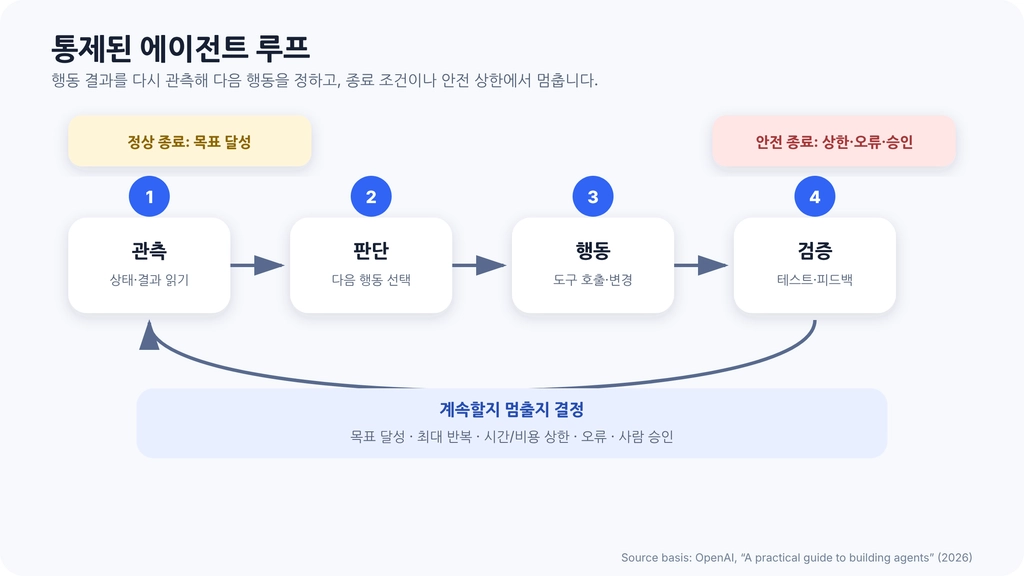

## 루프의 정의와 ReAct
- **루프**: 목표를 달성할 때까지 생각 → 행동 → 결과 확인을 반복하는 구조
- **ReAct (Reasoning + Acting)**
  - 추론과 행동을 번갈아 수행하는 방식
  - `Thought → Action → Observation` 반복
  - 행동 결과를 보고 다음 생각을 수정할 수 있음

## 루프의 구성 요소
- **목표**: 무엇을 달성해야 하는지
- **상태**: 지금까지의 진행 상황, 컨텍스트
- **행동**: 도구 호출 등 실제 수행하는 작업
- **관찰**: 행동 결과를 다시 모델에 전달
- **종료 조건**: 언제 멈출지

## 루프에서 증폭되는 실패

| 패턴 | 사용 상황 | 종료 조건 | 안전 상한 |
|---|---|---|---|
| 재시도 | 일시적 오류 (예: `DB_TIMEOUT`, `retryable: true`) | 성공하면 종료 | 최대 재시도 횟수, 재시도 간격 |
| 주기 실행 | 매일 아침 리포트 생성 | 해당 회차 작업 완료 | 회차당 시간, 비용 상한, 실패 시 알림 |
| 이벤트 트리거 | 코드가 올라오면 자동 리뷰 | 리뷰 작성 완료 | 같은 이벤트 중복 실행 방지, 회당 시간 상한 |
| 목표 달성까지 반복 | 레거시 API 마이그레이션 | 레거시 API 사용 0건 & 전체 테스트 통과 | 반복 횟수, 시간, 비용 상한 |

## 통제 장치와 실행 단계
- **통제 장치**
  - 최대 반복 횟수 제한
  - 토큰·비용 예산



- **실행 단계**
  1. **계획**: 목표를 작은 단계로 나눔
  2. **실행**: 도구 호출 등 행동 수행
  3. **관찰**: 결과 확인
  4. **검증**: 목표에 가까워졌는지 판단
  5. **반복 또는 종료**: 종료 조건을 만족하면 끝, 아니면 1번으로